<a href="https://colab.research.google.com/github/mohammadbadi/CrimeAnalytics_Clustering/blob/main/Code%20Sections/6.1.1%203D%20Visualizations%20of%20Top%205%20Clusters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Code Sections/6.1 3D Visualizations of Top 5 Clusters.ipynb**

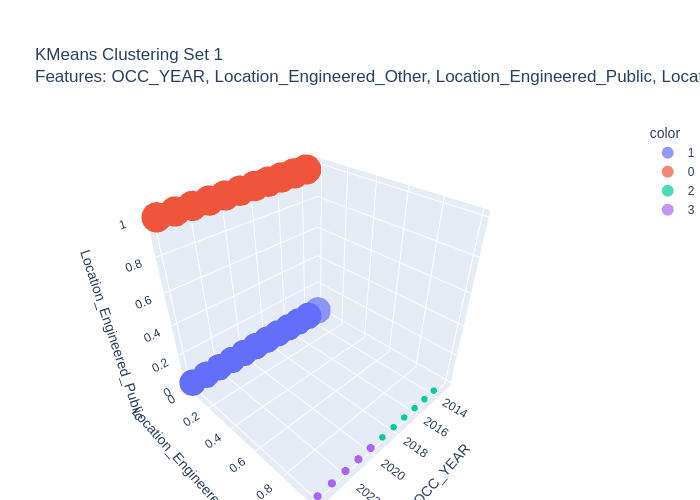

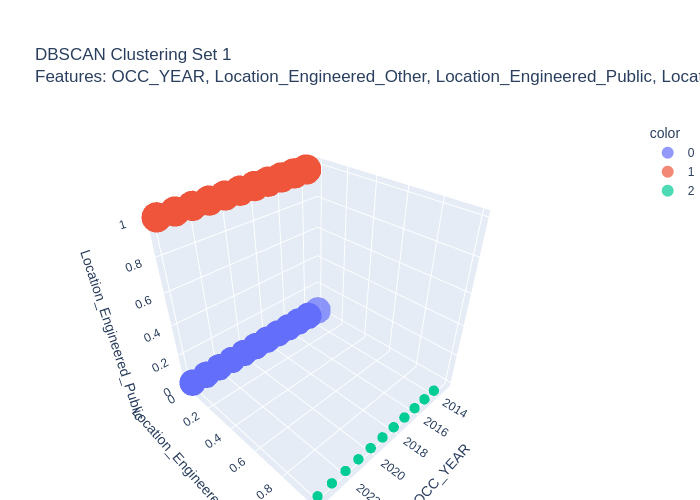

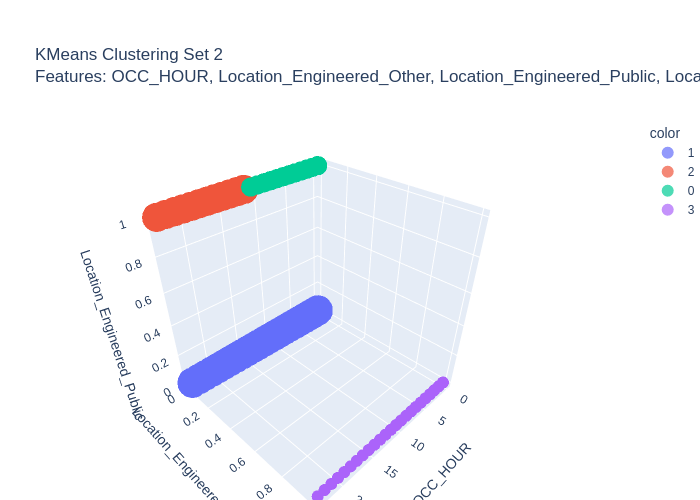

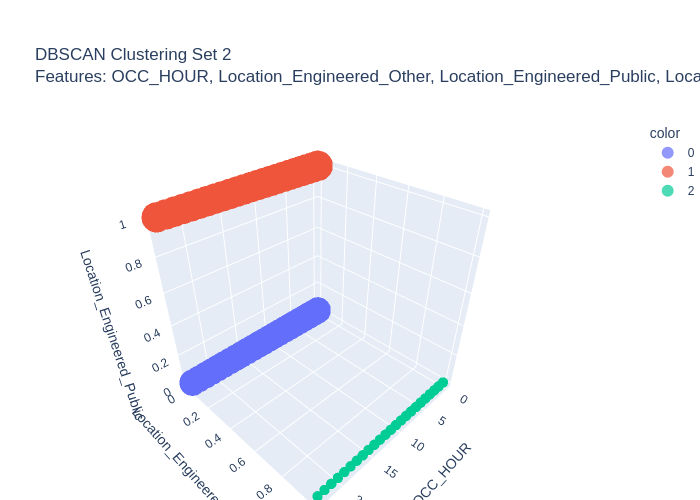

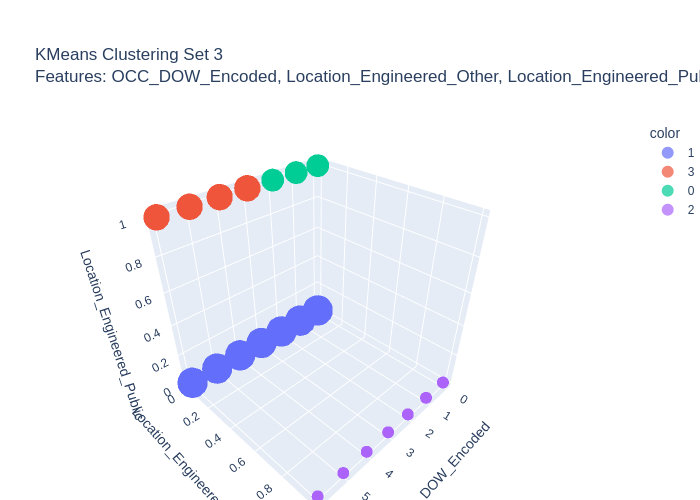

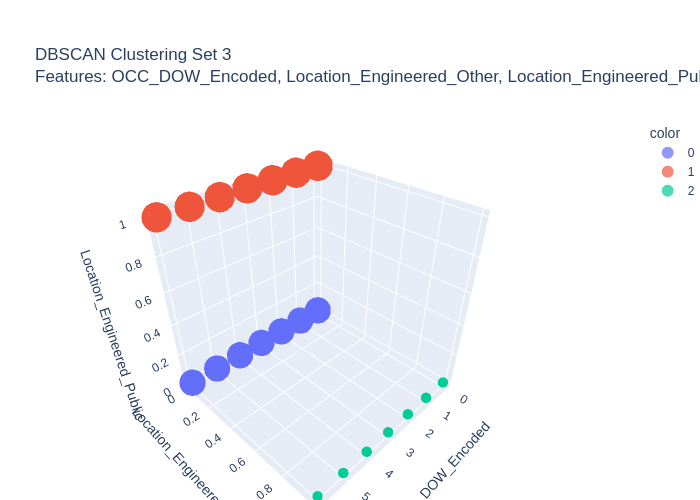

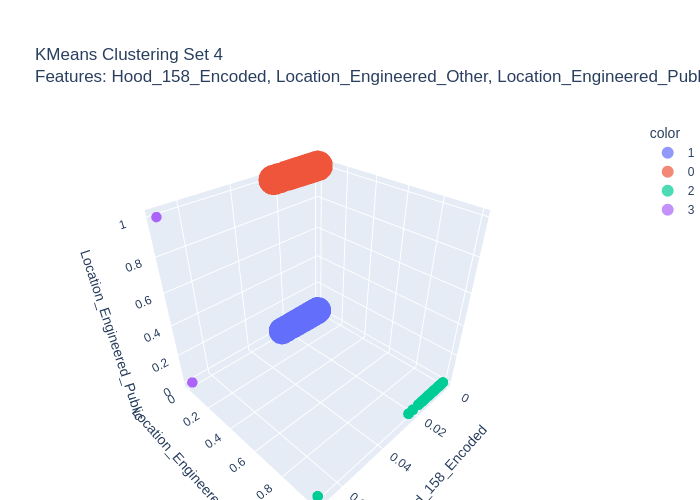

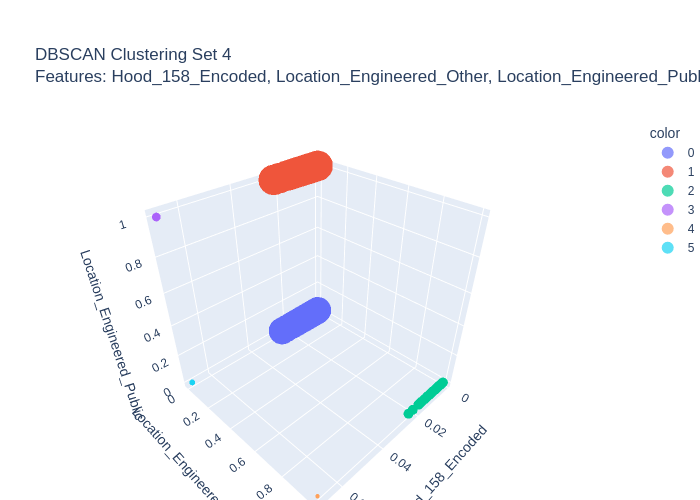

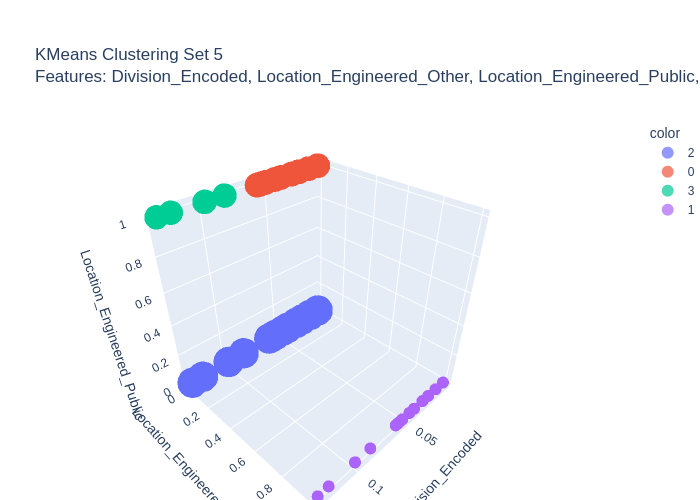

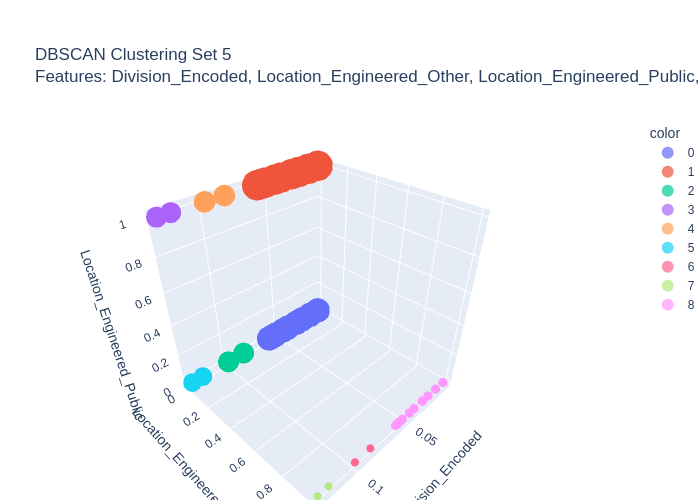

In [2]:
# if you counter any error then Install kaleido if not already available
# After Installation restart the runtime and then run this code
!pip install -q kaleido

import pandas as pd
import plotly.express as px
from IPython.display import display, HTML, Image
import ast

# Load the datasets
url = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Clustering_Base_Features.csv"
url1 = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Clustering_Result_Stats.csv"
url2 = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Feature_Combo_Current_Results.csv"

# Read the feature dataset and clustering statistics, then merge them on "_id"
features_df = pd.read_csv(url)
clustering_stats_df = pd.read_csv(url1)
clustering_results = pd.merge(features_df, clustering_stats_df, on="_id", how="left")

# Load feature combinations
feature_combos = pd.read_csv(url2)

# Define the set names to match
set_names = ['4_Set_165','4_Set_369', '4_Set_490', '4_Set_494', '4_Set_495']

# Extract corresponding feature sets (list of features for each set)
feature_sets = []
for set_name in set_names:
    matched_features = feature_combos[feature_combos['Feature Set'] == set_name]['Feature_Names_String']
    if not matched_features.empty:
        features_list = ast.literal_eval(matched_features.values[0])
        feature_sets.append(features_list)

# Loop over each clustering set (5 sets)
for i in range(1, 6):
    # Define cluster column names
    kmeans_cluster_col = f'KMeans{i}_Cluster'
    dbscan_cluster_col = f'DBSCAN{i}_Cluster'

    # Use the first three features for the 3D plots
    features_used = feature_sets[i - 1]

    # Retrieve the scores from the first row of clustering_results
    # KMeans scores:
    kmeans_sil = clustering_results[f'KMeans{i}_Silhouette_Score'].iloc[0]
    kmeans_db  = clustering_results[f'KMeans{i}_Davies_Bouldin_Index'].iloc[0]
    kmeans_ch  = clustering_results[f'KMeans{i}_Calinski_Harabasz_Score'].iloc[0]
    kmeans_acc = clustering_results[f'KMeans{i}_Prediction_Accuracy'].iloc[0]
    # DBSCAN scores:
    dbscan_sil = clustering_results[f'DBSCAN{i}_Silhouette_Score'].iloc[0]
    dbscan_db  = clustering_results[f'DBSCAN{i}_Davies_Bouldin_Index'].iloc[0]
    dbscan_acc = clustering_results[f'DBSCAN{i}_Prediction_Accuracy'].iloc[0]

    # Format the score strings
    kmeans_scores_text = (f"Silhouette: {kmeans_sil:.3f}, Davies-Bouldin: {kmeans_db:.3f}, "
                           f"Calinski-Harabasz: {kmeans_ch:.0f}, Accuracy: {kmeans_acc:.2f}%")
    dbscan_scores_text = (f"Silhouette: {dbscan_sil:.3f}, Davies-Bouldin: {dbscan_db:.3f}, "
                           f"Accuracy: {dbscan_acc:.2f}%")

    # Create a score info string for each plot
    score_info_kmeans = f"Features: {', '.join(features_used)} {kmeans_scores_text}"
    score_info_dbscan  = f"Features: {', '.join(features_used)} {dbscan_scores_text}"

    # Identify rows with valid cluster values (non-NaN and not -1) for KMeans:
    valid_kmeans_data = clustering_results[
        clustering_results[kmeans_cluster_col].notna() &
        (clustering_results[kmeans_cluster_col] != -1) &
        clustering_results[features_used[0]].notna() &
        clustering_results[features_used[1]].notna() &
        clustering_results[features_used[2]].notna()
    ]

    # Identify rows for DBSCAN similarly:
    valid_dbscan_data = clustering_results[
        clustering_results[dbscan_cluster_col].notna() &
        (clustering_results[dbscan_cluster_col] != -1) &
        clustering_results[features_used[0]].notna() &
        clustering_results[features_used[1]].notna() &
        clustering_results[features_used[2]].notna()
    ]

    # For KMeans: compute cluster sizes (number of rows per cluster)
    if not valid_kmeans_data.empty:
        cluster_sizes = valid_kmeans_data.groupby(kmeans_cluster_col).size().rename('cluster_size')
        valid_kmeans_data = valid_kmeans_data.merge(cluster_sizes, left_on=kmeans_cluster_col, right_index=True)

        # Create the 3D scatter plot for KMeans with marker sizes reflecting cluster size
        fig_kmeans = px.scatter_3d(
            valid_kmeans_data,
            x=features_used[0],
            y=features_used[1],
            z=features_used[2],
            color=valid_kmeans_data[kmeans_cluster_col].astype(str),
            size='cluster_size',
            size_max=50,
            title=f"KMeans Clustering Set {i}<br>{score_info_kmeans}"
        )
        # Remove marker white borders by setting marker_line_width to 0
        fig_kmeans.update_traces(marker_line_width=0)
        # Update layout margin to prevent title cropping
        fig_kmeans.update_layout(margin=dict(l=0, r=0, t=120, b=0))
        # Show interactive 3D figure
        fig_kmeans.show()

        # Save static image and display it
        filename_kmeans = f"kmeans_cluster_set_{i}.png"
        fig_kmeans.write_image(filename_kmeans)
        display(Image(filename_kmeans))

    # For DBSCAN: compute cluster sizes and create the plot similarly.
    if not valid_dbscan_data.empty:
        cluster_sizes = valid_dbscan_data.groupby(dbscan_cluster_col).size().rename('cluster_size')
        valid_dbscan_data = valid_dbscan_data.merge(cluster_sizes, left_on=dbscan_cluster_col, right_index=True)

        fig_dbscan = px.scatter_3d(
            valid_dbscan_data,
            x=features_used[0],
            y=features_used[1],
            z=features_used[2],
            color=valid_dbscan_data[dbscan_cluster_col].astype(str),
            size='cluster_size',
            size_max=50,
            title=f"DBSCAN Clustering Set {i}<br>{score_info_dbscan}"
        )
        # Remove the marker border as well:
        fig_dbscan.update_traces(marker_line_width=0)
        # Update layout margin to prevent title cropping
        fig_dbscan.update_layout(margin=dict(l=0, r=0, t=120, b=0))
        # Show interactive 3D figure
        fig_dbscan.show()

        # Save static image and display it
        filename_dbscan = f"dbscan_cluster_set_{i}.png"
        fig_dbscan.write_image(filename_dbscan)
        display(Image(filename_dbscan))

# Optionally, display a message indicating that all visualizations have been rendered
display(HTML("<h3>Interactive and static visualizations of Top Clustering Models have been rendered.</h3>"))
